# Proyek Akhir: Menyelesaikan Permasalahan Perusahaan Edutech

- Nama: Alaika Izatul Ilmi 
- Email: alaikaizatulilmi@gmail.com
- Id Dicoding: alaika_izatul_ilmi

## Latar Belakang & Tujuan

Jaya Jaya Institut menghadapi jumlah **dropout yang tinggi**. Tujuan proyek ini adalah membangun model *machine learning* yang dapat **mendeteksi sedini mungkin mahasiswa yang berisiko dropout**, sehingga institusi dapat memberi bimbingan khusus sebelum terlambat.

**Pertanyaan bisnis**
1. Faktor apa yang paling membedakan mahasiswa dropout dengan yang tidak?
2. Seberapa baik model dapat mengenali calon dropout, dan seberapa dini?
3. Bagaimana hasil model dapat dipakai untuk memprioritaskan bimbingan (bahan dashboard berikutnya)?

**Keputusan desain utama**
- Target dibuat **biner** (Dropout vs bukan Dropout). Kasus salah-negatif (siswa berisiko tak terdeteksi) lebih merugikan daripada salah-positif (siswa dibimbing padahal aman), sehingga metrik utama adalah **recall kelas Dropout** dan **PR-AUC**, bukan accuracy.
- Dibuat dua skenario: **model penuh** (data s/d semester 2) dan **model peringatan dini** (data pendaftaran + semester 1).

## Persiapan

### Menyiapkan library yang dibutuhkan

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve, fbeta_score,
                             precision_score, recall_score, f1_score, accuracy_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


### Menyiapkan data yang akan diguankan

Berkas `data.csv` memakai pemisah titik koma (`;`) dan diawali karakter BOM, sehingga dibaca dengan `sep=";"` dan `encoding="utf-8-sig"`.

In [2]:
# File memakai pemisah titik koma (;) dan diawali BOM, sehingga perlu sep=";" dan encoding="utf-8-sig"
df = pd.read_csv("data.csv", sep=";", encoding="utf-8-sig")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (4424, 37)


,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nacionality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Admission_grade,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,Age_at_enrollment,International,Curricular_units_1st_sem_credited,Curricular_units_1st_sem_enrolled,Curricular_units_1st_sem_evaluations,Curricular_units_1st_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_1st_sem_without_evaluations,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Data Understanding

### Struktur & kualitas data
Dataset berisi **4.424 mahasiswa** dengan **36 fitur** + kolom `Status`. Fitur mencakup data pendaftaran, demografi, sosial-ekonomi, finansial, performa akademik semester 1 dan 2, serta indikator makroekonomi. Kolom seperti `Course`, `Application_mode`, `Marital_status`, `Mothers_occupation` dkk. adalah **kode kategori**, bukan angka berurutan.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Marital_status                                4424 non-null   int64  
 1   Application_mode                              4424 non-null   int64  
 2   Application_order                             4424 non-null   int64  
 3   Course                                        4424 non-null   int64  
 4   Daytime_evening_attendance                    4424 non-null   int64  
 5   Previous_qualification                        4424 non-null   int64  
 6   Previous_qualification_grade                  4424 non-null   float64
 7   Nacionality                                   4424 non-null   int64  
 8   Mothers_qualification                         4424 non-null   int64  
 9   Fathers_qualification                         4424 non-null   int64  
 10 

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital_status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application_mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application_order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime_evening_attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous_qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mothers_qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Fathers_qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [5]:
print("Total missing value :", df.isna().sum().sum())
print("Baris duplikat      :", df.duplicated().sum())
print("Kolom konstan       :", [c for c in df.columns if df[c].nunique() == 1])
print()
print("Distribusi Status:")
status = df["Status"].value_counts().to_frame("jumlah")
status["persen"] = (status["jumlah"] / len(df) * 100).round(2)
status

Total missing value : 0
Baris duplikat      : 0
Kolom konstan       : []

Distribusi Status:


,jumlah,persen
Status,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


**Temuan kualitas data:** tidak ada missing value, tidak ada duplikat, dan tidak ada kolom konstan, jadi data bersih secara struktur. Kelas **Dropout = 32,1%** (1.421 mahasiswa), **Graduate = 49,9%**, **Enrolled = 18,0%**. Ketidakseimbangan kelas moderat, sehingga ditangani dengan `class_weight="balanced"`, stratified split, dan metrik yang sesuai.

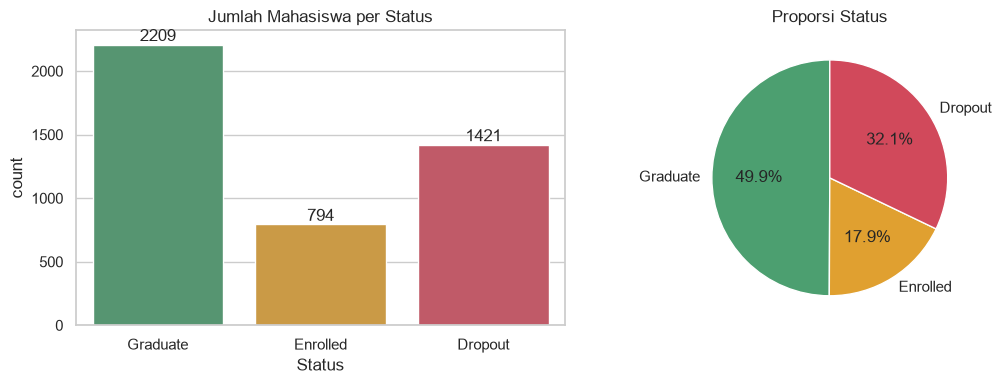

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ["Graduate", "Enrolled", "Dropout"]
colors = {"Graduate": "#4C9F70", "Enrolled": "#E0A030", "Dropout": "#D1495B"}
sns.countplot(data=df, x="Status", order=order, palette=colors, ax=ax[0])
ax[0].set_title("Jumlah Mahasiswa per Status")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[1].pie(df["Status"].value_counts()[order], labels=order, autopct="%1.1f%%", colors=[colors[o] for o in order], startangle=90)
ax[1].set_title("Proporsi Status")
plt.tight_layout()

### Faktor finansial dan demografis

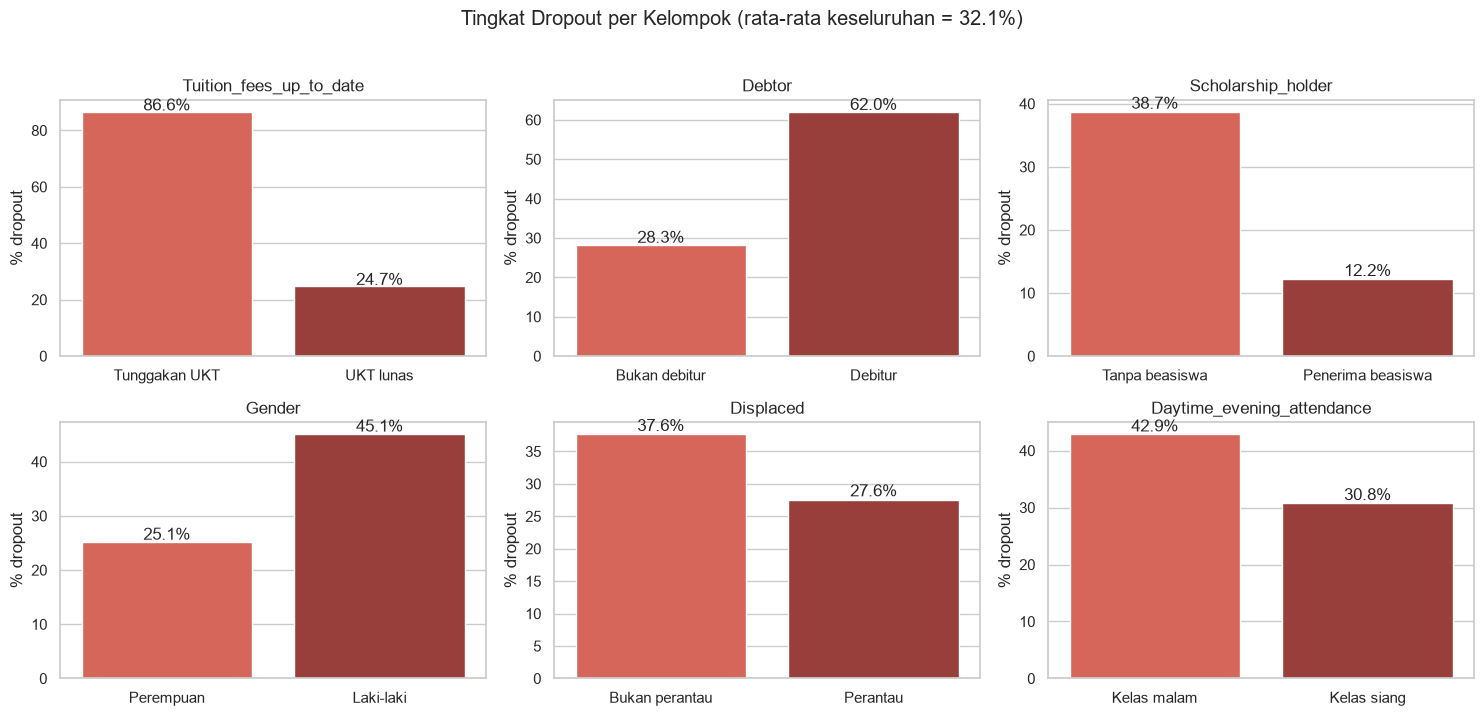

In [7]:
# Tingkat dropout berdasarkan faktor administratif / finansial / demografis
df["is_dropout"] = (df["Status"] == "Dropout").astype(int)
label_map = {
    "Tuition_fees_up_to_date": {0: "Tunggakan UKT", 1: "UKT lunas"},
    "Debtor": {0: "Bukan debitur", 1: "Debitur"},
    "Scholarship_holder": {0: "Tanpa beasiswa", 1: "Penerima beasiswa"},
    "Gender": {0: "Perempuan", 1: "Laki-laki"},
    "Displaced": {0: "Bukan perantau", 1: "Perantau"},
    "Daytime_evening_attendance": {0: "Kelas malam", 1: "Kelas siang"},
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (col, mp) in zip(axes.ravel(), label_map.items()):
    rate = df.groupby(col)["is_dropout"].mean().rename(index=mp) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette="Reds_d")
    ax.set_title(col); ax.set_ylabel("% dropout"); ax.set_xlabel("")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.suptitle("Tingkat Dropout per Kelompok (rata-rata keseluruhan = %.1f%%)" % (df["is_dropout"].mean() * 100), y=1.02)
plt.tight_layout()

**Temuan:**
- **Tunggakan UKT** adalah sinyal sangat kuat: dropout **86,6%** pada yang menunggak vs **24,7%** pada yang lunas.
- **Debitur** dropout **62,0%** vs 28,3% non-debitur.
- **Penerima beasiswa** hanya dropout **12,2%** vs 38,7% tanpa beasiswa.
- **Laki-laki** dropout 45,1% vs perempuan 25,1%; **kelas malam** 42,9% vs kelas siang 30,8%.
- Usia saat mendaftar: dropout 21% (≤20 th) naik menjadi sekitar 60% (25-30 th), yaitu mahasiswa yang lebih tua jauh lebih berisiko.

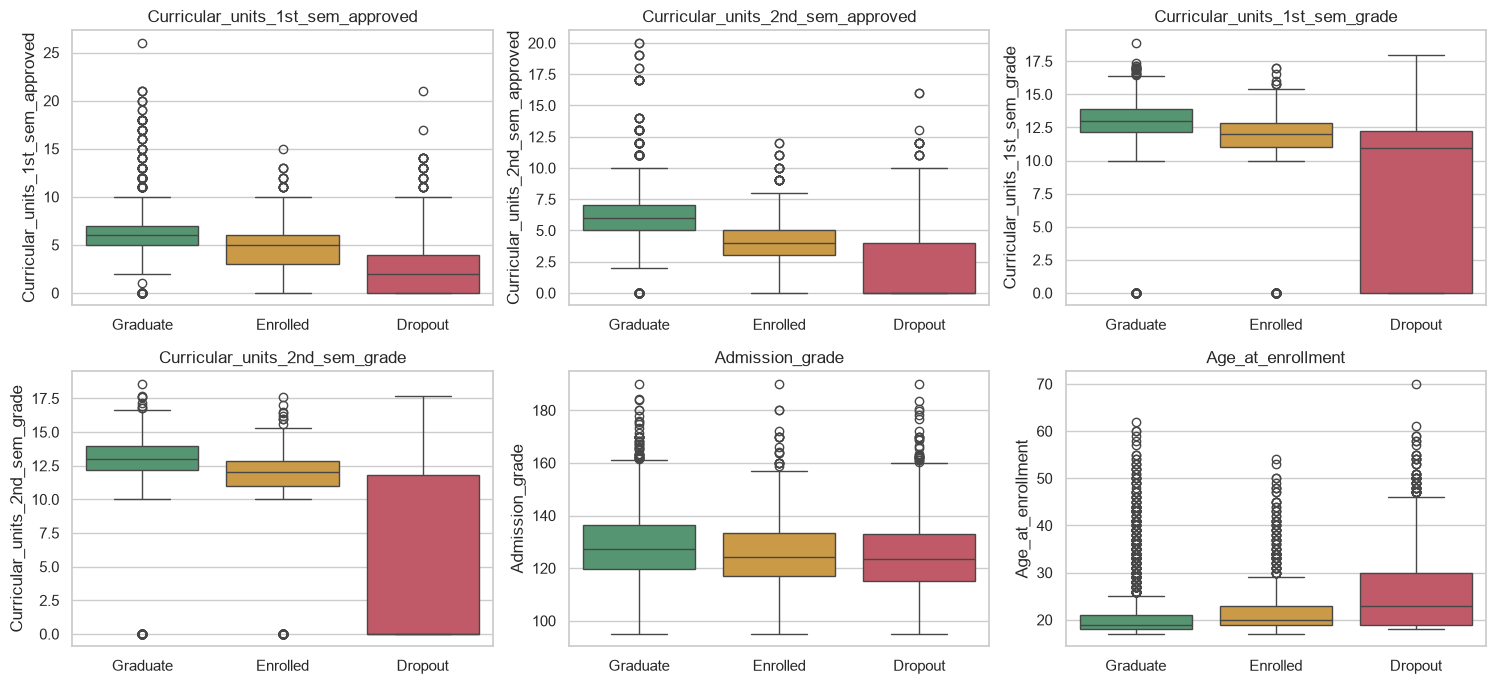

In [8]:
# Performa akademik semester 1 & 2 vs status
cols = ["Curricular_units_1st_sem_approved", "Curricular_units_2nd_sem_approved",
        "Curricular_units_1st_sem_grade", "Curricular_units_2nd_sem_grade",
        "Admission_grade", "Age_at_enrollment"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x="Status", y=c, order=order, palette=colors, ax=ax)
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout()

In [9]:
# Perbandingan 3 kelas pada fitur akademik kunci (rata-rata)
df.groupby("Status")[["Curricular_units_1st_sem_approved", "Curricular_units_2nd_sem_approved",
                      "Curricular_units_1st_sem_grade", "Curricular_units_2nd_sem_grade",
                      "Tuition_fees_up_to_date", "Scholarship_holder", "Debtor", "Age_at_enrollment"]].mean().round(2)

,Curricular_units_1st_sem_approved,Curricular_units_2nd_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_2nd_sem_grade,Tuition_fees_up_to_date,Scholarship_holder,Debtor,Age_at_enrollment
Status,,,,,,,,
Dropout,2.55,1.94,7.26,5.90,0.68,0.09,0.22,26.07
Enrolled,4.32,4.06,11.13,11.12,0.95,0.16,0.11,22.37
Graduate,6.23,6.18,12.64,12.70,0.99,0.38,0.05,21.78


**Temuan akademik:** mahasiswa Dropout rata-rata hanya meluluskan **2,55** mata kuliah di semester 1 dan **1,94** di semester 2 (Graduate: 6,23 dan 6,18), dengan nilai rata-rata jauh lebih rendah. Sebanyak 16% mahasiswa tidak lulus satu pun mata kuliah semester 1, dan **79,4%** dari mereka dropout (vs 23,0% pada yang lulus minimal satu). Sinyal dropout sudah terlihat sejak **semester 1**, sehingga peringatan dini memang layak dilakukan.

Kelas **Enrolled** profilnya berada di antara Graduate dan Dropout, tetapi lebih dekat ke Graduate pada UKT, beasiswa, dan jumlah mata kuliah lulus. Ini mendukung keputusan menggabungkannya ke kelas "bukan Dropout".

In [10]:
# Tingkat dropout per program studi (kode Course), hanya yang punya >= 50 mahasiswa
course = df.groupby("Course")["is_dropout"].agg(["count", "mean"])
course = course[course["count"] >= 50].sort_values("mean", ascending=False)
course["mean"] = (course["mean"] * 100).round(1)
course.rename(columns={"count": "jumlah_mhs", "mean": "dropout_%"})

,jumlah_mhs,dropout_%
Course,,
9130,141,55.3
9119,170,54.1
9991,268,50.7
9853,192,44.3
9003,210,41.0
9556,86,38.4
171,215,38.1
9254,252,38.1
9670,268,35.4


Tingkat dropout sangat bervariasi antar program studi, dari **15,4%** (kode 9500) hingga **55,3%** (kode 9130). `Course` dipertahankan sebagai fitur dan menjadi dimensi penting untuk dashboard.

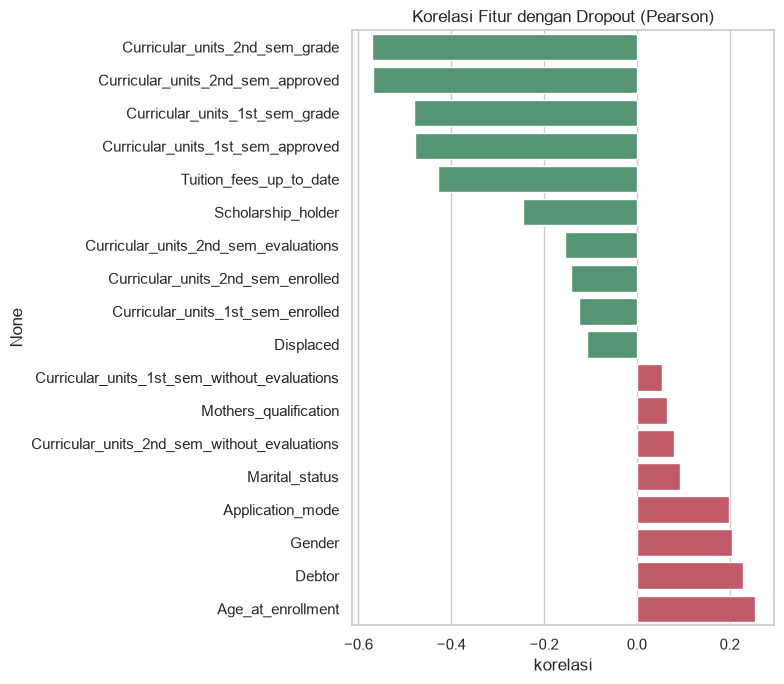

In [11]:
corr = df.drop(columns=["Status"]).corr()["is_dropout"].drop("is_dropout").sort_values()
top = pd.concat([corr.head(10), corr.tail(8)])
plt.figure(figsize=(8, 7))
sns.barplot(x=top.values, y=top.index, palette=["#4C9F70" if v < 0 else "#D1495B" for v in top.values])
plt.title("Korelasi Fitur dengan Dropout (Pearson)")
plt.xlabel("korelasi")
plt.tight_layout()

## Data Preparation / Preprocessing

### 1. Definisi target
Status `Dropout` diberi label 1; `Graduate` dan `Enrolled` diberi label 0.

In [12]:
# Target biner: 1 = Dropout, 0 = bukan Dropout (Graduate + Enrolled)
# Alasan: tujuan bisnis adalah mendeteksi siswa berisiko dropout. Siswa 'Enrolled' belum selesai studi
# dan belum terbukti dropout, sehingga digabung ke kelas negatif.
df = df.drop(columns=["is_dropout"])
df["target"] = (df["Status"] == "Dropout").astype(int)
print(df["target"].value_counts(normalize=True).round(3))

target
0    0.679
1    0.321
Name: proportion, dtype: float64


### 2. Feature engineering
Dibuat fitur turunan: **tingkat kelulusan MK** per semester (approved/enrolled), rasio evaluasi per MK, **total MK lulus**, serta **tren** jumlah MK lulus dan nilai dari semester 1 ke 2. Pembagian dilakukan aman dari pembagian-nol (enrolled = 0 diisi 0).

In [13]:
# Feature engineering berbasis performa akademik
for s in ["1st", "2nd"]:
    enr = df[f"Curricular_units_{s}_sem_enrolled"].replace(0, np.nan)
    df[f"Approval_rate_{s}_sem"] = (df[f"Curricular_units_{s}_sem_approved"] / enr).fillna(0)
    df[f"Eval_to_enrolled_{s}_sem"] = (df[f"Curricular_units_{s}_sem_evaluations"] / enr).fillna(0)

df["Total_approved"] = df["Curricular_units_1st_sem_approved"] + df["Curricular_units_2nd_sem_approved"]
df["Approved_trend"] = df["Curricular_units_2nd_sem_approved"] - df["Curricular_units_1st_sem_approved"]
df["Grade_trend"] = df["Curricular_units_2nd_sem_grade"] - df["Curricular_units_1st_sem_grade"]

df[["Approval_rate_1st_sem", "Approval_rate_2nd_sem", "Total_approved", "Approved_trend", "Grade_trend"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Approval_rate_1st_sem,4424.0,0.697885,0.365247,0.000000,0.5,0.833333,1.000000,1.0
Approval_rate_2nd_sem,4424.0,0.660356,0.382964,0.000000,0.4,0.833333,1.000000,1.0
Total_approved,4424.0,9.142405,5.960612,0.000000,5.0,10.000000,12.000000,43.0
Approved_trend,4424.0,-0.270796,1.340645,-9.000000,-1.0,0.000000,0.000000,6.0
Grade_trend,4424.0,-0.410616,2.890376,-16.142857,-0.6,0.000000,0.452381,16.0


### 3. Pemilihan kolom
- **Nominal** (kode kategori) di-*one-hot encode*; kategori yang muncul <15 kali digabung agar model tidak overfit pada kode langka.
- **Numerik/biner** distandarisasi.
- `early_cols` = fitur tanpa informasi semester 2, untuk model peringatan dini.

In [14]:
nominal_cols = ["Marital_status", "Application_mode", "Course", "Previous_qualification", "Nacionality",
                "Mothers_qualification", "Fathers_qualification", "Mothers_occupation", "Fathers_occupation"]
feature_cols = [c for c in df.columns if c not in ("Status", "target")]
numeric_cols = [c for c in feature_cols if c not in nominal_cols]

# Skenario "peringatan dini": hanya data saat pendaftaran + semester 1
engineered_2nd = ["Approval_rate_2nd_sem", "Eval_to_enrolled_2nd_sem", "Total_approved", "Approved_trend", "Grade_trend"]
early_cols = [c for c in feature_cols if "2nd_sem" not in c and c not in engineered_2nd]

print("Fitur total   :", len(feature_cols), "| nominal:", len(nominal_cols), "| numerik/biner:", len(numeric_cols))
print("Fitur early   :", len(early_cols))

Fitur total   : 43 | nominal: 9 | numerik/biner: 34
Fitur early   : 32


### 4. Split data & preprocessor
Data dibagi **80% train / 20% test** secara stratified. Seluruh preprocessing berada di dalam `Pipeline`, sehingga statistik scaling/encoding hanya dipelajari dari data train (**tanpa data leakage**).

In [15]:
X, y = df[feature_cols], df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| dropout %.1f%%" % (y_train.mean() * 100))
print("Test :", X_test.shape, "| dropout %.1f%%" % (y_test.mean() * 100))

def make_preprocessor(num_cols, nom_cols):
    """Standarisasi fitur numerik + one-hot untuk kode kategori (kategori langka <15 data digabung)."""
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15, sparse_output=False), nom_cols),
    ])

preprocessor = make_preprocessor(numeric_cols, nominal_cols)
print("Dimensi setelah preprocessing:", preprocessor.fit_transform(X_train).shape)

Train: (3539, 43) | dropout 32.1%
Test : (885, 43) | dropout 32.1%
Dimensi setelah preprocessing: (3539, 132)


## Modeling

### 1. Baseline tiga model
Dibandingkan model linear (**Logistic Regression**) dan dua model *ensemble* berbasis pohon (**Random Forest**, **Hist Gradient Boosting**) dengan 5-fold stratified cross-validation pada data train. Semua memakai `class_weight="balanced"`.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def build(model, num_cols=numeric_cols, nom_cols=nominal_cols):
    return Pipeline([("prep", make_preprocessor(num_cols, nom_cols)), ("clf", model)])

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "precision": "precision", "f1": "f1"}

rows = []
for name, m in base_models.items():
    r = cross_validate(build(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring}})
baseline = pd.DataFrame(rows).set_index("model").round(4)
baseline

,roc_auc,pr_auc,recall,precision,f1
model,,,,,
Logistic Regression,0.9214,0.8836,0.8127,0.7659,0.7882
Random Forest,0.9178,0.8722,0.7106,0.8714,0.7828
Hist Gradient Boosting,0.9177,0.8791,0.7880,0.8163,0.8016


Ketiga model berkinerja sangat mirip (ROC-AUC sekitar 0,92). Artinya sinyal dropout pada data ini kuat dan relatif linear, sehingga model sederhana pun sudah memadai.

### 2. Hyperparameter tuning
`RandomizedSearchCV` (12 kombinasi per model, 5-fold) dengan metrik **PR-AUC** (average precision), yang lebih sensitif terhadap performa pada kelas minoritas dibanding ROC-AUC.

In [17]:
param_space = {
    "Logistic Regression": {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    "Random Forest": {"clf__n_estimators": [300, 500], "clf__max_depth": [6, 10, 14, None],
                      "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.3]},
    "Hist Gradient Boosting": {"clf__learning_rate": [0.02, 0.05, 0.1], "clf__max_depth": [2, 3, 4, None],
                               "clf__max_leaf_nodes": [8, 15, 31], "clf__min_samples_leaf": [10, 20, 40],
                               "clf__l2_regularization": [0, 1, 5], "clf__max_iter": [100, 200, 300]},
}
tuned, rows = {}, []
for name, m in base_models.items():
    search = RandomizedSearchCV(build(m), param_space[name], n_iter=12, scoring="average_precision",
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    tuned[name] = search
    rows.append({"model": name, "best_cv_pr_auc": search.best_score_, "best_params": search.best_params_})
tuning = pd.DataFrame(rows).set_index("model")
tuning["best_cv_pr_auc"] = tuning["best_cv_pr_auc"].round(4)
pd.set_option("display.max_colwidth", 200)
tuning

,best_cv_pr_auc,best_params
model,,
Logistic Regression,0.8836,{'clf__C': 1}
Random Forest,0.8705,"{'clf__n_estimators': 500, 'clf__min_samples_leaf': 5, 'clf__max_features': 0.3, 'clf__max_depth': None}"
Hist Gradient Boosting,0.8812,"{'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 100, 'clf__max_depth': 4, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0}"


### 3. Pemilihan model & threshold
Model terbaik dipilih berdasarkan **PR-AUC cross-validation** (bukan data test, agar test tetap objektif). Hasilnya **Logistic Regression**, unggul tipis dan sekaligus paling mudah dijelaskan, yang penting untuk dipercaya staf akademik.

Threshold keputusan dipilih dari prediksi *out-of-fold* data train dengan memaksimalkan **F2-score** (recall dihargai 2x precision), selaras dengan prioritas bisnis agar calon dropout tidak terlewat.

Model terpilih: Logistic Regression
Parameter     : {'clf__C': 1}
Threshold optimal (maks. F2 pada OOF) = 0.23


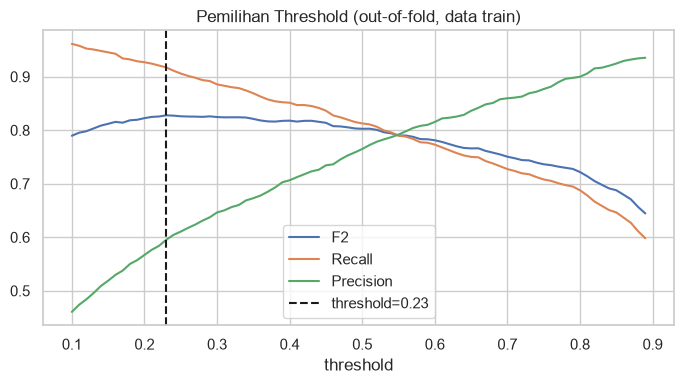

In [18]:
best_name = tuning["best_cv_pr_auc"].idxmax()
best_model = tuned[best_name].best_estimator_
print("Model terpilih:", best_name)
print("Parameter     :", tuned[best_name].best_params_)

# Pilih threshold dari prediksi out-of-fold pada data train (bukan data test -> tidak bocor).
# Prioritas bisnis: recall dropout tinggi (jangan sampai siswa berisiko terlewat), maka dipakai F2 (recall 2x lebih penting).
oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.arange(0.10, 0.90, 0.01)
f2 = [fbeta_score(y_train, oof >= t, beta=2) for t in thresholds]
THRESHOLD = float(thresholds[int(np.argmax(f2))])
print(f"Threshold optimal (maks. F2 pada OOF) = {THRESHOLD:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f2, label="F2")
plt.plot(thresholds, [recall_score(y_train, oof >= t) for t in thresholds], label="Recall")
plt.plot(thresholds, [precision_score(y_train, oof >= t) for t in thresholds], label="Precision")
plt.axvline(THRESHOLD, color="k", ls="--", label=f"threshold={THRESHOLD:.2f}")
plt.xlabel("threshold"); plt.legend(); plt.title("Pemilihan Threshold (out-of-fold, data train)")
plt.tight_layout()

In [19]:
best_model.fit(X_train, y_train)
print("Model final telah dilatih pada data train.")

Model final telah dilatih pada data train.


## Evaluation

### 1. Performa pada data test (data yang belum pernah dilihat model)

In [20]:
proba_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= THRESHOLD).astype(int)

metrics = {
    "model": best_name, "threshold": THRESHOLD,
    "accuracy": accuracy_score(y_test, pred_test),
    "precision_dropout": precision_score(y_test, pred_test),
    "recall_dropout": recall_score(y_test, pred_test),
    "f1_dropout": f1_score(y_test, pred_test),
    "f2_dropout": fbeta_score(y_test, pred_test, beta=2),
    "roc_auc": roc_auc_score(y_test, proba_test),
    "pr_auc": average_precision_score(y_test, proba_test),
}
print(f"Model: {metrics['model']} | threshold: {metrics['threshold']:.2f}")
print(pd.Series({k: v for k, v in metrics.items() if k not in ("model", "threshold")}).round(4).to_string())
print()
print(classification_report(y_test, pred_test, target_names=["Tidak Dropout", "Dropout"]))

Model: Logistic Regression | threshold: 0.23
accuracy             0.7785
precision_dropout    0.6019
recall_dropout       0.9155
f1_dropout           0.7263
f2_dropout           0.8291
roc_auc              0.9315
pr_auc               0.9014

               precision    recall  f1-score   support

Tidak Dropout       0.95      0.71      0.81       601
      Dropout       0.60      0.92      0.73       284

     accuracy                           0.78       885
    macro avg       0.77      0.81      0.77       885
 weighted avg       0.84      0.78      0.79       885



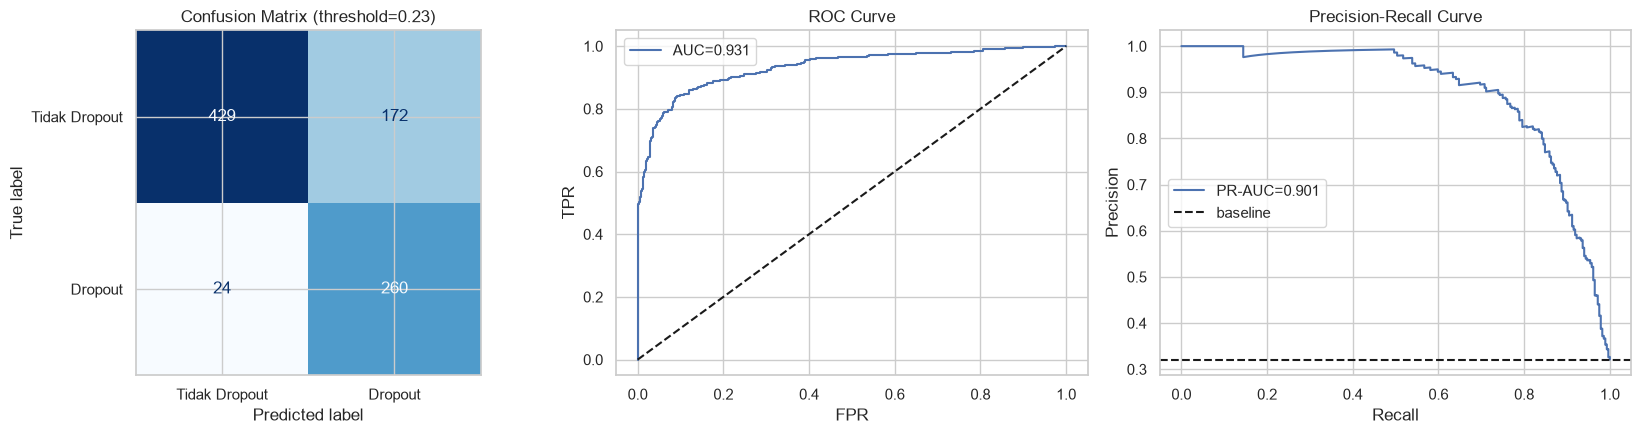

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Tidak Dropout", "Dropout"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion Matrix (threshold={THRESHOLD:.2f})")
fpr, tpr, _ = roc_curve(y_test, proba_test)
ax[1].plot(fpr, tpr, label=f"AUC={metrics['roc_auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_title("ROC Curve"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
p, r, _ = precision_recall_curve(y_test, proba_test)
ax[2].plot(r, p, label=f"PR-AUC={metrics['pr_auc']:.3f}"); ax[2].axhline(y_test.mean(), color="k", ls="--", label="baseline")
ax[2].set_title("Precision-Recall Curve"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].legend()
plt.tight_layout()

**Interpretasi:**
- Model menangkap **91,6% mahasiswa yang benar-benar dropout** (recall), dengan ROC-AUC **0,93** dan PR-AUC **0,90**.
- Konsekuensinya, precision **60,2%**: dari 10 mahasiswa yang ditandai, sekitar 6 benar-benar dropout. Ini *trade-off* yang disengaja; menawarkan bimbingan kepada siswa yang sebenarnya aman biayanya jauh lebih kecil daripada kehilangan siswa yang tak terdeteksi.
- Accuracy (77,9%) sengaja tidak dijadikan acuan utama karena threshold digeser untuk mengutamakan recall.

In [22]:
# Perbandingan ketiga model tuned pada data test dengan threshold default 0.5 (perbandingan setara)
rows = []
for name, s in tuned.items():
    pr = s.best_estimator_.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    rows.append({"model": name, "roc_auc": roc_auc_score(y_test, pr), "pr_auc": average_precision_score(y_test, pr),
                 "recall@0.5": recall_score(y_test, pr >= 0.5), "precision@0.5": precision_score(y_test, pr >= 0.5),
                 "f1@0.5": f1_score(y_test, pr >= 0.5)})
compare = pd.DataFrame(rows).set_index("model").round(4)
compare

,roc_auc,pr_auc,recall@0.5,precision@0.5,f1@0.5
model,,,,,
Logistic Regression,0.9315,0.9014,0.8451,0.7973,0.8205
Random Forest,0.9338,0.9023,0.8063,0.8327,0.8193
Hist Gradient Boosting,0.9377,0.9101,0.8345,0.7848,0.8089


Pada threshold 0,5, ketiga model tuned kembali hampir setara di data test (selisih ROC-AUC sekitar 0,01-0,02). Logistic Regression tetap dipakai karena pemilihan dilakukan lewat validasi silang dan modelnya paling transparan. Jika kelak performa maksimal lebih penting daripada interpretabilitas, Hist Gradient Boosting adalah alternatif yang layak.

### 2. Faktor paling berpengaruh
Dihitung dengan *permutation importance* pada kolom asli sehingga langsung bisa dibaca oleh pihak non-teknis dan dipakai sebagai dasar tampilan dashboard.

,feature,importance,std
0,Tuition_fees_up_to_date,0.055407,0.005913
1,Approval_rate_2nd_sem,0.047921,0.005555
2,Total_approved,0.047842,0.005850
3,Curricular_units_2nd_sem_approved,0.045118,0.005002
4,Curricular_units_1st_sem_approved,0.044594,0.006033
5,Curricular_units_2nd_sem_enrolled,0.023292,0.003648
6,Unemployment_rate,0.010858,0.002351
7,Course,0.007842,0.002195
8,Curricular_units_1st_sem_enrolled,0.007652,0.002407
9,Curricular_units_1st_sem_credited,0.007072,0.001750


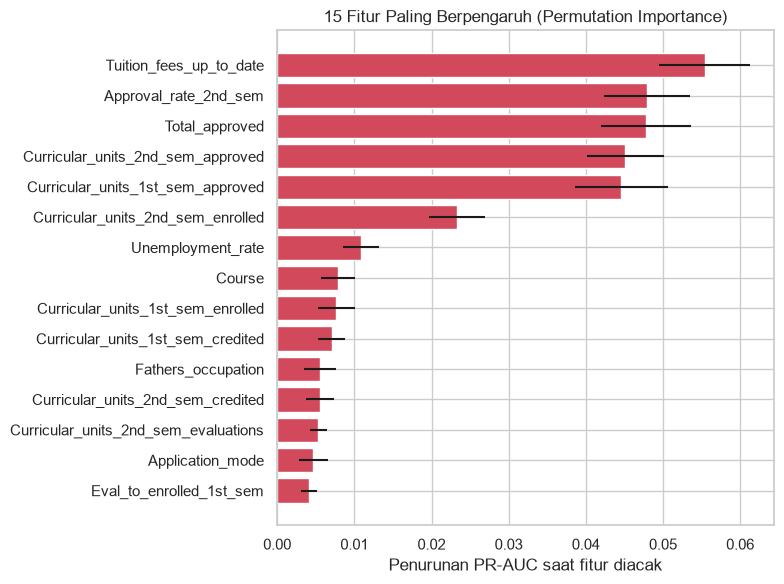

In [23]:
# Permutation importance pada data test, dihitung terhadap kolom ASLI (bukan hasil one-hot) -> mudah dibaca untuk dashboard
perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision", n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
importance.to_csv("outputs/feature_importance.csv", index=False)

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#D1495B")
plt.xlabel("Penurunan PR-AUC saat fitur diacak"); plt.title("15 Fitur Paling Berpengaruh (Permutation Importance)")
plt.tight_layout()
importance.head(15)

**Interpretasi:** prediktor teratas adalah **status UKT**, diikuti **kelulusan mata kuliah** (tingkat kelulusan semester 2, total MK lulus, MK lulus semester 1 dan 2), lalu jumlah MK yang diambil, **tingkat pengangguran**, dan **program studi**. Dengan kata lain, dropout terutama dipicu **masalah finansial** dan **kegagalan akademik awal**, sehingga intervensi paling tepat ada di dua area tersebut.

### 3. Skenario peringatan dini (hanya data s/d semester 1)
Model penuh memakai data semester 2, padahal bimbingan akan lebih efektif bila diberikan lebih awal. Berikut dibandingkan dengan model yang hanya memakai data pendaftaran dan semester 1.

In [24]:
# Skenario peringatan dini: hanya data pendaftaran + semester 1 (tanpa semester 2)
early_model = build(tuned[best_name].best_estimator_.named_steps["clf"].__class__(**tuned[best_name].best_estimator_.named_steps["clf"].get_params()),
                    num_cols=[c for c in numeric_cols if c in early_cols], nom_cols=nominal_cols)
oof_e = cross_val_predict(early_model, X_train[early_cols], y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
thr_e = float(thresholds[int(np.argmax([fbeta_score(y_train, oof_e >= t, beta=2) for t in thresholds]))])
early_model.fit(X_train[early_cols], y_train)
pe = early_model.predict_proba(X_test[early_cols])[:, 1]
early_metrics = {"model": best_name, "threshold": thr_e,
                 "precision_dropout": precision_score(y_test, pe >= thr_e), "recall_dropout": recall_score(y_test, pe >= thr_e),
                 "f1_dropout": f1_score(y_test, pe >= thr_e), "roc_auc": roc_auc_score(y_test, pe), "pr_auc": average_precision_score(y_test, pe)}
pd.DataFrame({"Model penuh (s/d semester 2)": {k: metrics[k] for k in early_metrics if k != "model"},
              "Model peringatan dini (s/d semester 1)": {k: early_metrics[k] for k in early_metrics if k != "model"}}).round(4)

,Model penuh (s/d semester 2),Model peringatan dini (s/d semester 1)
threshold,0.2300,0.2900
precision_dropout,0.6019,0.6053
recall_dropout,0.9155,0.8908
f1_dropout,0.7263,0.7208
roc_auc,0.9315,0.9128
pr_auc,0.9014,0.8737


**Interpretasi:** model peringatan dini hanya sedikit lebih lemah (recall **89,1%** vs 91,6%; ROC-AUC **0,913** vs 0,932). Jadi mayoritas calon dropout sudah dapat dikenali **setelah semester 1**, satu semester lebih awal, dengan kehilangan akurasi yang kecil. **Model ini yang direkomendasikan untuk operasional**, sedangkan model penuh bisa dipakai sebagai pembaruan risiko di akhir semester 2.

### 4. Segmentasi tingkat risiko (untuk prioritas bimbingan)
Skor probabilitas dikelompokkan menjadi tiga tingkat: **Rendah** (di bawah threshold), **Sedang** (threshold sampai 0,5), **Tinggi** (≥ 0,5).

In [25]:
# Segmentasi tingkat risiko -> bahan langsung untuk dashboard & prioritas bimbingan
# Rendah  : skor < threshold (tidak ditandai model)
# Sedang  : threshold <= skor < 0.5 (ditandai, perlu dipantau)
# Tinggi  : skor >= 0.5 (prioritas bimbingan)
def risk_tier(p):
    return pd.cut(p, bins=[-0.01, THRESHOLD, 0.5, 1.01], right=False, labels=["Rendah", "Sedang", "Tinggi"])

tier = pd.DataFrame({"proba": proba_test, "actual": y_test.values})
tier["tier"] = risk_tier(tier["proba"])
tier_summary = tier.groupby("tier", observed=True).agg(jumlah_mhs=("actual", "size"), dropout_aktual=("actual", "sum"),
                                                        persen_dropout=("actual", "mean")).round(3)
tier_summary["persen_dari_seluruh_dropout"] = (tier_summary["dropout_aktual"] / tier["actual"].sum()).round(3)
tier_summary

,jumlah_mhs,dropout_aktual,persen_dropout,persen_dari_seluruh_dropout
tier,,,,
Rendah,453,24,0.053,0.085
Sedang,131,20,0.153,0.070
Tinggi,301,240,0.797,0.845


**Interpretasi:** kelompok **Tinggi** berisi sekitar sepertiga mahasiswa (301 dari 885) tetapi mencakup **84,5% seluruh dropout**, dengan 79,7% di antaranya benar-benar dropout. Staf bimbingan dapat memulai dari kelompok ini. Kelompok **Rendah** hanya memiliki 5,3% dropout, jadi aman untuk pemantauan rutin.

### 5. Ekspor artefak untuk tahap dashboard
Semua mahasiswa diberi skor risiko memakai prediksi *out-of-fold*, sehingga skor tiap mahasiswa dihasilkan oleh model yang tidak pernah melihat datanya.

In [26]:
# Skor risiko untuk SELURUH mahasiswa memakai prediksi out-of-fold (setiap mahasiswa diskor oleh model yang tidak melihat datanya)
oof_all = cross_val_predict(build(best_model.named_steps["clf"].__class__(**best_model.named_steps["clf"].get_params())),
                            X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
scored = df.copy()
scored["risk_score"] = oof_all.round(4)
scored["risk_tier"] = risk_tier(scored["risk_score"]).astype(str)
scored["predicted_dropout"] = (scored["risk_score"] >= THRESHOLD).astype(int)
scored.to_csv("outputs/data_dengan_skor_risiko.csv", index=False)

joblib.dump({"model": best_model, "threshold": THRESHOLD, "feature_cols": feature_cols, "numeric_cols": numeric_cols,
             "nominal_cols": nominal_cols}, "outputs/model_dropout.joblib")
early_model_bundle = {"model": early_model, "threshold": thr_e, "feature_cols": early_cols}
joblib.dump(early_model_bundle, "outputs/model_dropout_early_warning.joblib")
with open("outputs/metrics.json", "w") as f:
    json.dump({"model_penuh": {k: (float(v) if not isinstance(v, str) else v) for k, v in metrics.items()},
               "model_early_warning": {k: (float(v) if not isinstance(v, str) else v) for k, v in early_metrics.items()}}, f, indent=2)
print("Tersimpan di folder outputs/:", sorted(os.listdir("outputs")))
scored[["Status", "risk_score", "risk_tier", "predicted_dropout"]].head()

Tersimpan di folder outputs/: ['data_dengan_skor_risiko.csv', 'feature_importance.csv', 'metrics.json', 'model_dropout.joblib', 'model_dropout_early_warning.joblib']


,Status,risk_score,risk_tier,predicted_dropout
0,Dropout,0.7317,Tinggi,1
1,Graduate,0.5425,Tinggi,1
2,Dropout,0.9991,Tinggi,1
3,Graduate,0.1909,Rendah,0
4,Graduate,0.0820,Rendah,0


## Kesimpulan & Rekomendasi

**Hasil model**
- Model terpilih: **Logistic Regression** (5-fold CV, tuned). Pada data test: **recall Dropout 91,6%**, precision 60,2%, ROC-AUC 0,93, PR-AUC 0,90.
- Model **peringatan dini** (s/d semester 1) tetap kuat: recall 89,1%, ROC-AUC 0,91.

**Faktor risiko utama:** tunggakan UKT / status debitur, sedikitnya mata kuliah yang lulus pada semester 1-2, usia pendaftaran yang lebih tua, tidak memiliki beasiswa, program studi tertentu, dan kelas malam.

**Rekomendasi aksi untuk institusi**
1. Jalankan skrining **di akhir semester 1** dan beri bimbingan prioritas pada mahasiswa berisiko **Tinggi**.
2. Siapkan **jalur bantuan finansial** (cicilan UKT, beasiswa) untuk mahasiswa yang menunggak, karena ini sinyal terkuat.
3. Beri **pendampingan akademik** bagi mahasiswa yang gagal pada sebagian besar MK semester 1.
4. Beri perhatian ekstra pada **program studi dengan dropout tinggi** serta mahasiswa **usia lebih tua** dan **kelas malam**.

**Bahan untuk dashboard (folder `outputs/`)**
| Berkas | Isi |
|---|---|
| `data_dengan_skor_risiko.csv` | Seluruh mahasiswa + `risk_score`, `risk_tier`, `predicted_dropout` |
| `feature_importance.csv` | Peringkat faktor berpengaruh |
| `metrics.json` | Metrik model penuh & peringatan dini |
| `model_dropout.joblib`, `model_dropout_early_warning.joblib` | Model + threshold untuk prediksi mahasiswa baru |

**Keterbatasan**
- Model memprediksi **risiko**, bukan sebab; faktor seperti UKT bersifat korelatif.
- Precision sekitar 60% berarti sebagian mahasiswa yang ditandai sebenarnya aman; bimbingan sebaiknya bersifat suportif, bukan sanksi.
- Data berasal dari satu institusi dan periode tertentu; model perlu dipantau dan dilatih ulang secara berkala.
- Variabel sensitif (gender, kebangsaan, status disabilitas) sebaiknya tidak dipakai untuk memutuskan perlakuan individu; gunakan untuk memantau keadilan model.